In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def f(x):
    return x**2 + 2*x + 1

In [5]:
f(3.0)

16.0

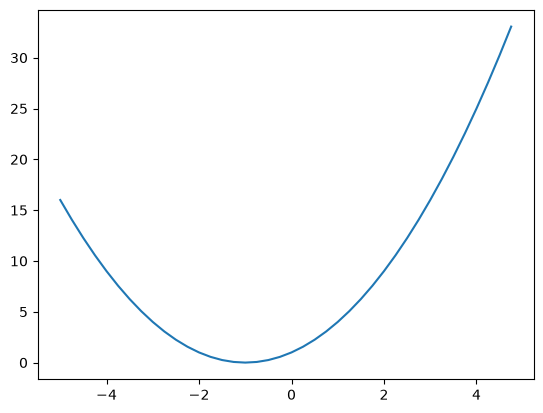

In [10]:
xs = np.arange(-5, 5, 0.25)
ys= f(xs)
plt.plot(xs, ys)

In [31]:
h = 0.00001
x = -1.0
(f(x + h) - f(x)) / h

1.000000082740371e-05

In [27]:
# lets get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [33]:
h = 0.0001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print("d1:", d1)
print("d2:", d2)
print("numerical gradient:", (d2 - d1) / h)

d1: 4.0
d2: 3.999699999999999
numerical gradient: -3.000000000010772


In [112]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self.grad = 0.0
        self._op = _op
        self.label = label
        self._backward = lambda: None #by default, the backward function does nothing

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad =  out.grad
            other.grad = out.grad
        out._backward = _backward

        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad
        out._backward = _backward

        return out

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        return out

In [72]:
a = Value(2.0, label='a')
print(a)
b = Value(-3.0, label='b')
print(b)
print(a + b)

c = Value(10.0, label='c')
e=a*b; e.label='e'
d = e + c; d.label='d'
print(d)

f=Value(-2.0, label='f')
L = d*f; L.label='L'
print(L)

Value(data=2.0, grad=0.0)
Value(data=-3.0, grad=0.0)
Value(data=-1.0, grad=0.0)
Value(data=4.0, grad=0.0)
Value(data=-8.0, grad=0.0)


In [73]:
d._prev

{Value(data=-6.0, grad=0.0), Value(data=10.0, grad=0.0)}

In [74]:
d._op   

'+'

In [75]:
from graphviz import Digraph

def trace(root):
    """
    builds a set of all nodes and edges in a graph
    """
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    nodes, edges = trace(root)    
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph,create a rectangular ('record') node for it
        dot.node(name = uid, label = "{%s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

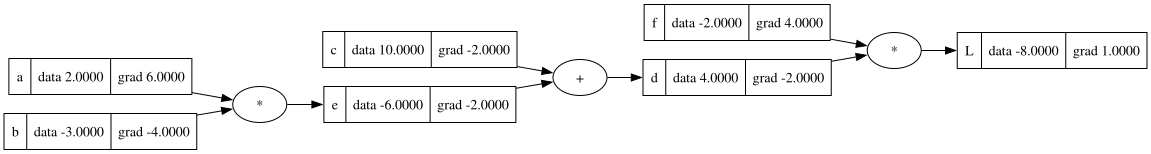

In [92]:
draw_dot(L)

dL/dd = f

In [86]:
L.grad = 1.0
f.grad = 4.0
d.grad = -2.0

dL/dc = dL/dd dd/dc

In [88]:
c.grad = -2.0
e.grad = -2.0

In [91]:
a.grad = 6.0
b.grad = -4.0

In [81]:
def lol():
    
    h=0.01
    
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b
    e.label = 'e'
    d = e + c
    d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f
    L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b
    e.label = 'e'
    d = e + c
    d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f
    L.label = 'L'
    L2 = L.data + h

    print("L1:", L1)
    print("L2:", L2)
    print("numerical gradient:", (L2 - L1) / h)

lol()

L1: -8.0
L2: -7.99
numerical gradient: 0.9999999999999787


Text(0, 0.5, 'tanh(x)')

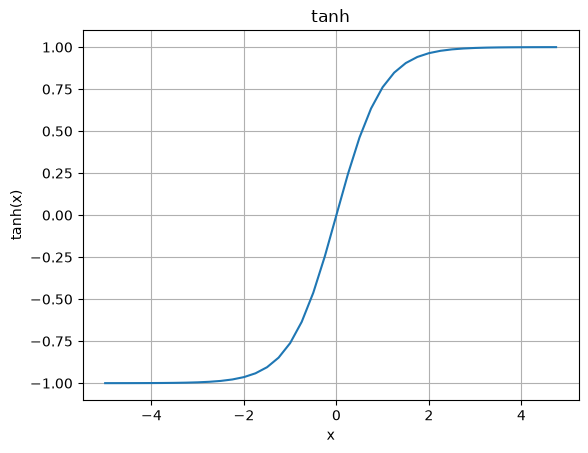

In [93]:
plt.plot(np.arange(-5, 5, 0.25), np.tanh(np.arange(-5, 5, 0.25))); plt.grid(); plt.title("tanh"); plt.xlabel("x"); plt.ylabel("tanh(x)")

In [118]:
# inputs x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813735870195432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label ='x1w1'
x2w2 = x2*w2; x2w2.label ='x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2+b; n.label='n'

o = n.tanh()
o.label = 'o'

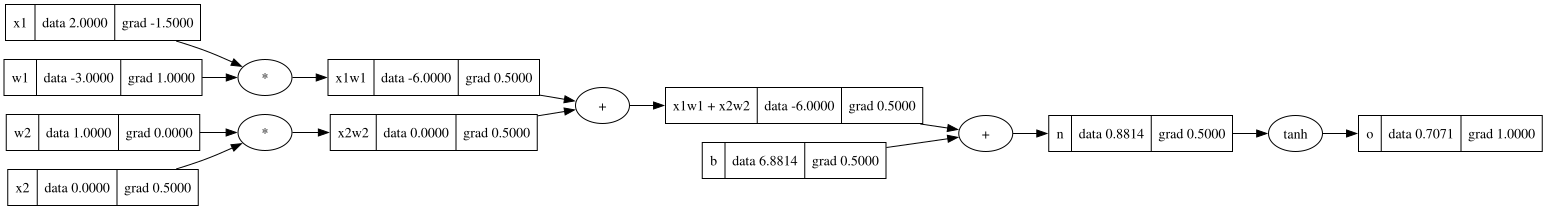

In [130]:
draw_dot(o)

In [110]:
o.grad = 1.0

In [108]:
# o = tanh(n)
# do/dn = 1 - tanh^2(n) = 1 - o^2
n.grad = 0.5

alright this is all manual backpropagation but i already know calculus guys and doing this all manually is killing me with boredom, i tried to just do it anyways but it is such simple math for me right now rip lol

In [120]:
o.grad = 1.0
o._backward()

In [129]:
n._backward()
b._backward()
x1w1x2w2._backward()
x2w2._backward()
x1w1._backward()

ok yeah let me just be done with this and go to the pytorch